<a href="https://colab.research.google.com/github/mmosquera355/AvedexWeb/blob/master/P1LenetArchitecture_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imports

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as func
import PIL.ImageOps
from torch import nn
import torch.utils.data as data
from torchvision import datasets,transforms
import requests
from PIL import Image

import torch.nn.functional as F
import torch.optim as optim
import torchvision

from sklearn import decomposition
from sklearn import manifold
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

import copy
import random
import time

In [ ]:
SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# Data loader

In [ ]:
TRAIN_DATA_PATH = "./data/train/"
TEST_DATA_PATH = "./data/test/"


device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
transform1=transforms.Compose([transforms.Resize((35,35)),transforms.ToTensor(),transforms.Normalize((0.5,),(0.5,))])

train_data = torchvision.datasets.ImageFolder(root=TRAIN_DATA_PATH, transform=transform1)
#train_data_loader = data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4)
test_data = torchvision.datasets.ImageFolder(root=TEST_DATA_PATH, transform=transform1)
#test_data_loader  = data.DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
print("Number of train samples: ", len(train_data))
print("Number of test samples: ", len(test_data))
print("Detected Classes are: ", train_data.class_to_idx)
print("Detected Classes are: ", test_data.class_to_idx)

Number of train samples:  3609
Number of test samples:  639
Detected Classes are:  {'Amazilia_tzacatl': 0, 'Brotogeris_jugularis': 1, 'Buteo_magnirostris': 2, 'Columbina_talpacoti': 3, 'Coragyps_atratus': 4, 'Melanerpes_rubricapillus': 5, 'Pitangus_sulphuratus': 6, 'Tiaris_bicolor': 7, 'Tyrannus_melancholicus': 8}
Detected Classes are:  {'Amazilia_tzacatl': 0, 'Brotogeris_jugularis': 1, 'Buteo_magnirostris': 2, 'Columbina_talpacoti': 3, 'Coragyps_atratus': 4, 'Melanerpes_rubricapillus': 5, 'Pitangus_sulphuratus': 6, 'Tiaris_bicolor': 7, 'Tyrannus_melancholicus': 8}


In [ ]:
VALID_RATIO = 0.9

n_train_examples = int(len(train_data) * VALID_RATIO)
n_valid_examples = len(train_data) - n_train_examples

train_data, valid_data = data.random_split(train_data,
                                           [n_train_examples, n_valid_examples])

In [ ]:
valid_data = copy.deepcopy(valid_data)
valid_data.dataset.transform = transform1

In [ ]:
print(f'Number of training examples: {len(train_data)}')
print(f'Number of validation examples: {len(valid_data)}')
print(f'Number of testing examples: {len(test_data)}')


Number of training examples: 3248
Number of validation examples: 361
Number of testing examples: 639


In [ ]:
BATCH_SIZE = 100

train_iterator = data.DataLoader(train_data,
                                 shuffle = True,
                                 batch_size = BATCH_SIZE)

valid_iterator = data.DataLoader(valid_data,
                                 batch_size = BATCH_SIZE)

test_iterator = data.DataLoader(test_data,
                                shuffle = True,
                                batch_size = BATCH_SIZE)

In [ ]:
BATCH_SIZE = 64
test_iterator = data.DataLoader(test_data,
                                shuffle = True,
                                batch_size = BATCH_SIZE)

# construction of architecture

In [ ]:
class LeNet(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv1=nn.Conv2d(3,20,5,1)
            self.conv2=nn.Conv2d(20,50,5,1)
            self.fully1=nn.Linear(5*5*50,500)
            self.dropout1=nn.Dropout(0.5)
            self.fully2=nn.Linear(500,10)
        def forward(self,x):
            x=func.relu(self.conv1(x))
            x=func.max_pool2d(x,2,2)
            x=func.relu(self.conv2(x))
            x=func.max_pool2d(x,2,2)
            x=x.view(-1,5*5*50) #Reshaping the output into desired shape
            x=func.relu(self.fully1(x)) #Applying relu activation function to our first fully connected layer
            x=self.dropout1(x)
            x=self.fully2(x)    #We will not apply activation function here because we are dealing with multiclass dataset
            return x

In [ ]:
#model=LeNet().to(device)

#def count_parameters(model):
#    return sum(p.numel() for p in model.parameters() if p.requires_grad)

#print(f'The model has {count_parameters(model):,} trainable parameters')

The model has 657,080 trainable parameters


In [ ]:
def im_convert(tensor):
    image=tensor.cpu().clone().detach().numpy()
    image=image.transpose(1,2,0)
    #print(image.shape)
    image=image*(np.array((0.5,0.5,0.5))+np.array((0.5,0.5,0.5)))
    image=image.clip(0,1)
    return image


tensor([1, 7, 5, 7, 7, 0, 7, 8, 6, 4, 1, 0, 7, 2, 0, 7, 1, 8, 7, 3, 6, 5, 5, 2,
        8, 1, 6, 1, 3, 4, 5, 2, 1, 7, 2, 1, 4, 1, 1, 4, 5, 1, 5, 0, 3, 6, 3, 7,
        3, 7, 7, 7, 3, 5, 1, 3, 3, 6, 8, 4, 0, 3, 4, 3, 0, 6, 1, 4, 8, 3, 6, 2,
        8, 2, 3, 6, 6, 3, 6, 6, 8, 3, 5, 1, 2, 0, 8, 0, 4, 5, 8, 5, 7, 6, 0, 6,
        2, 2, 8, 0])


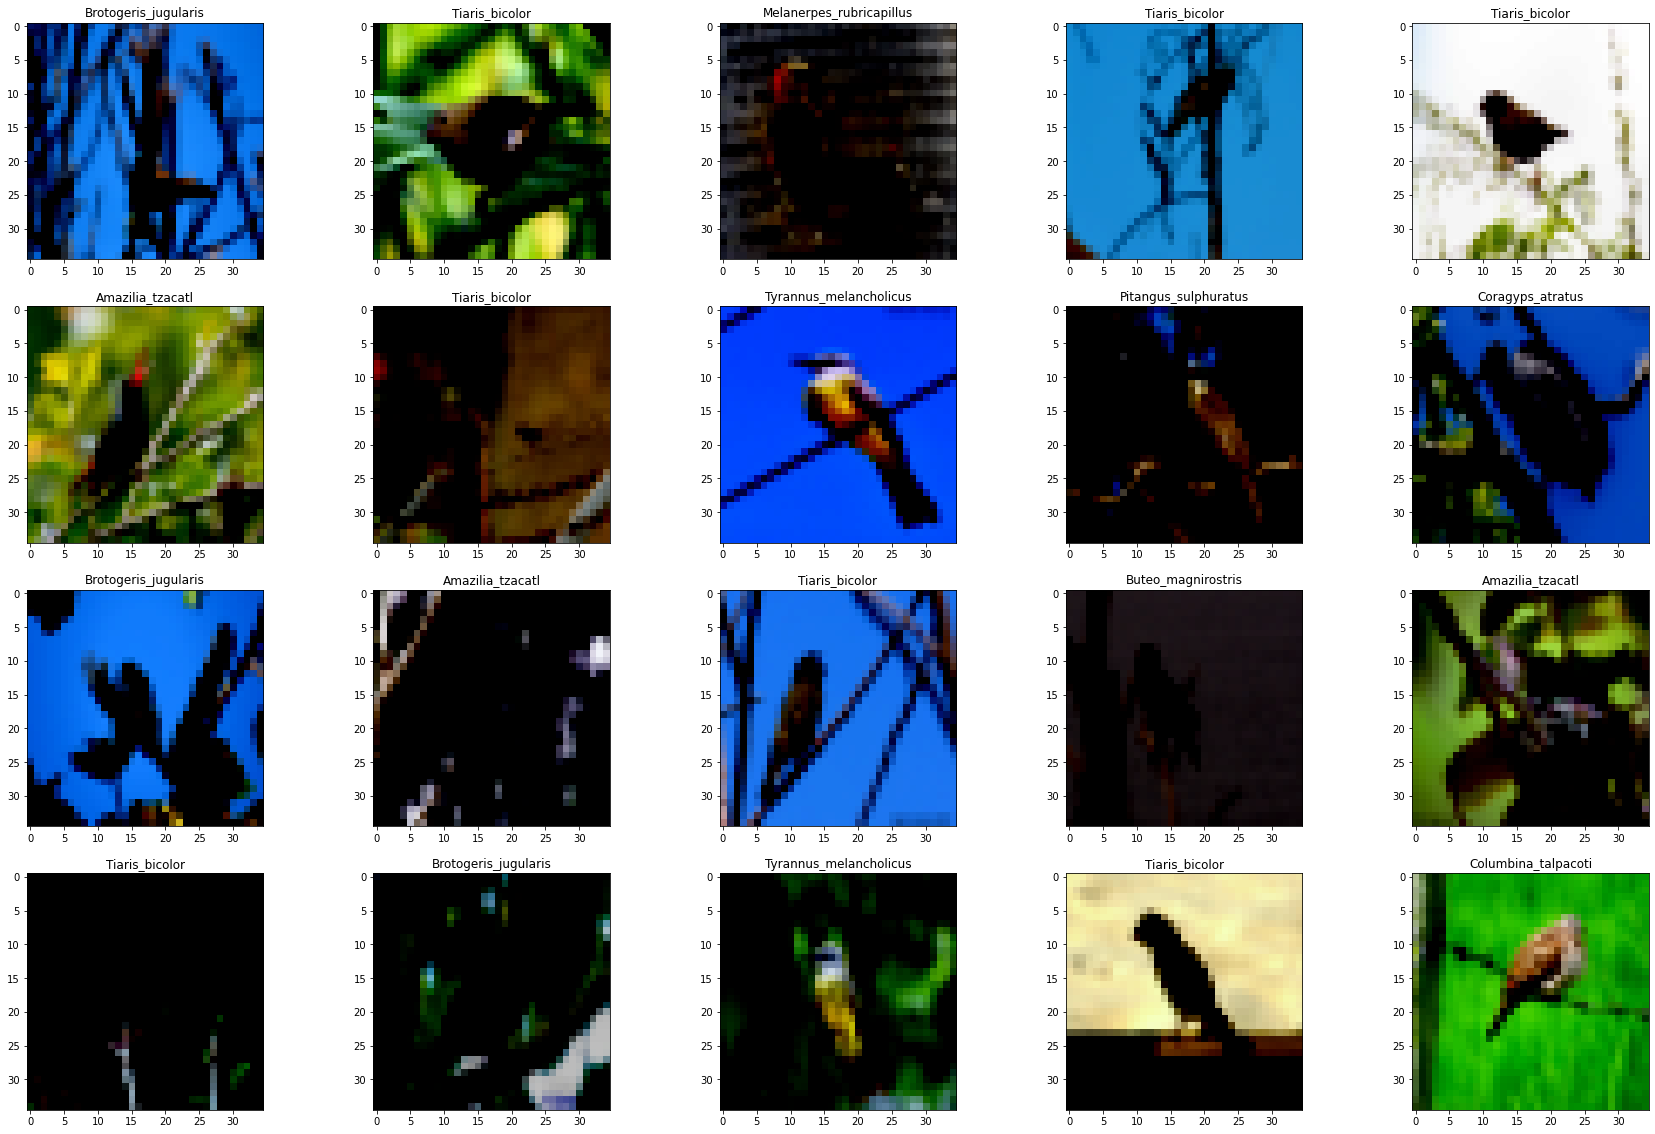

In [ ]:
classes=('Amazilia_tzacatl','Brotogeris_jugularis','Buteo_magnirostris','Columbina_talpacoti',
         'Coragyps_atratus','Melanerpes_rubricapillus','Pitangus_sulphuratus','Tiaris_bicolor','Tyrannus_melancholicus')
dataiter=iter(train_iterator)
images,labels=dataiter.next()
print(labels)

fig=plt.figure(figsize=(30,20))

for idx in np.arange(20):

    ax=fig.add_subplot(4,5,idx+1)
    plt.imshow(im_convert(images[idx]))
    ax.set_title(classes[labels[idx].item()])

In [ ]:
dataiter=iter(test_iterator)
images,labels=dataiter.next()
print(len(labels))

100


In [ ]:
model=LeNet().to(device)
criteron=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.00001)
epochs=20
loss_history=[]
correct_history=[]
val_loss_history=[]
val_correct_history=[]

In [ ]:
for e in range(epochs):
    loss=0.0

    correct=0.0
    val_loss=0.0
    val_correct=0.0

    for input,labels in train_iterator:
        input=input.to(device)

        labels=labels.to(device)

        outputs=model(input)

        loss1=criteron(outputs,labels)

        optimizer.zero_grad()

        loss1.backward()

        optimizer.step()

        _,preds=torch.max(outputs,1)

        loss+=loss1.item()

        correct+=torch.sum(preds==labels.data)

    else:
        with torch.no_grad():
            for val_input,val_labels in valid_iterator:

                val_input=val_input.to(device)

                val_labels=val_labels.to(device)

                val_outputs=model(val_input)

                val_loss1=criteron(val_outputs,val_labels)

                _,val_preds=torch.max(val_outputs,1)

                val_loss+=val_loss1.item()

                val_correct+=torch.sum(val_preds==val_labels.data)

        epoch_loss=loss/len(train_iterator)

        epoch_acc=correct.float()/len(train_iterator)

        loss_history.append(epoch_loss)

        correct_history.append(epoch_acc)

        val_epoch_loss=val_loss/len(valid_iterator)

        val_epoch_acc=val_correct.float()/len(valid_iterator)

        val_loss_history.append(val_epoch_loss)

        val_correct_history.append(val_epoch_acc)
        print(f'Epoch: {e+1:02}')
        print(f'\tTrain Loss: {epoch_loss:.3f} | Train Acc: {epoch_acc*100:.2f}%')
        print(f'\t Val. Loss: {val_epoch_loss:.3f} |  Val. Acc: {val_epoch_acc*100:.2f}%')

        print('training_loss:{:.4f},{:.4f}'.format(epoch_loss,epoch_acc.item()))
        print('validation_loss:{:.4f},{:.4f}'.format(val_epoch_loss,val_epoch_acc.item()))

c:\users\maria angelica\documents\proyecto de grado\desarrollo\entorno\lib\site-packages\PIL\Image.py:2835: DecompressionBombWarning: Image size (92257209 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  DecompressionBombWarning,


Epoch: 01
	Train Loss: 2.296 | Train Acc: 1121.21%
	 Val. Loss: 2.287 |  Val. Acc: 1100.00%
training_loss:2.2956,11.2121
validation_loss:2.2870,11.0000
Epoch: 02
	Train Loss: 2.283 | Train Acc: 1251.52%
	 Val. Loss: 2.273 |  Val. Acc: 1250.00%
training_loss:2.2830,12.5152
validation_loss:2.2734,12.5000
Epoch: 03
	Train Loss: 2.269 | Train Acc: 1448.48%
	 Val. Loss: 2.261 |  Val. Acc: 1225.00%
training_loss:2.2689,14.4848
validation_loss:2.2608,12.2500
Epoch: 04
	Train Loss: 2.254 | Train Acc: 1415.15%
	 Val. Loss: 2.246 |  Val. Acc: 1375.00%
training_loss:2.2541,14.1515
validation_loss:2.2457,13.7500
Epoch: 05
	Train Loss: 2.241 | Train Acc: 1536.36%
	 Val. Loss: 2.226 |  Val. Acc: 1725.00%
training_loss:2.2406,15.3636
validation_loss:2.2262,17.2500
Epoch: 06
	Train Loss: 2.226 | Train Acc: 1521.21%
	 Val. Loss: 2.209 |  Val. Acc: 1850.00%
training_loss:2.2258,15.2121
validation_loss:2.2087,18.5000
Epoch: 07
	Train Loss: 2.213 | Train Acc: 1496.97%
	 Val. Loss: 2.202 |  Val. Acc: 1550.

#  Examining the Model

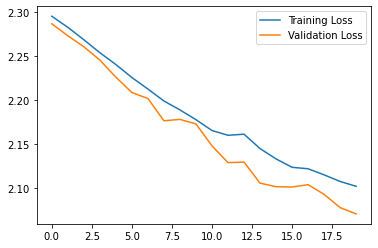

In [ ]:
plt.plot(loss_history,label='Training Loss')
plt.plot(val_loss_history,label='Validation Loss')
plt.legend()
plt.show()

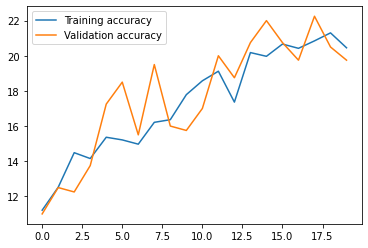

In [ ]:
plt.plot(correct_history,label='Training accuracy')
plt.plot(val_correct_history,label='Validation accuracy')
plt.legend()
plt.show()

In [ ]:
#Ejemplo de predicción Brotogeris_jugularis
#url='https://upload.wikimedia.org/wikipedia/commons/a/a1/Orange-chinned_Parakeet_%2816238697748%29.jpg'
#response=requests.get(url,stream=True)
img=Image.open("p1.jpg")
#img=Image.open(response.raw)
img=transform1(img)
image1=img.to(device).unsqueeze(0)
output=model(image1)
_,pred=torch.max(output,1)
print(classes[pred.item()])

Amazilia_tzacatl


In [ ]:
dataiter=iter(test_iterator)

images,labels=dataiter.next()

images_=images.to(device)

labels=labels.to(device)

print(labels)

output=model(images_)

_,preds=torch.max(output,1)



tensor([8, 7, 6, 1, 3, 3, 7, 5, 2, 5, 5, 4, 1, 5, 6, 8, 3, 6, 7, 6, 0, 7, 0, 3,
        4, 7, 0, 4, 2, 8, 8, 2, 7, 2, 4, 5, 5, 2, 1, 6, 4, 2, 2, 7, 0, 3, 1, 5,
        5, 4, 5, 1, 5, 5, 1, 3, 4, 2, 8, 7, 3, 4, 8, 3])


----------------------------------------------
prediccion Pitangus_sulphuratus
Real Tyrannus_melancholicus
----------------------------------------------
----------------------------------------------
prediccion Amazilia_tzacatl
Real Tiaris_bicolor
----------------------------------------------
----------------------------------------------
prediccion Coragyps_atratus
Real Pitangus_sulphuratus
----------------------------------------------
----------------------------------------------
prediccion Amazilia_tzacatl
Real Brotogeris_jugularis
----------------------------------------------
----------------------------------------------
prediccion Amazilia_tzacatl
Real Columbina_talpacoti
----------------------------------------------
----------------------------------------------
prediccion Amazilia_tzacatl
Real Columbina_talpacoti
----------------------------------------------
----------------------------------------------
prediccion Coragyps_atratus
Real Tiaris_bicolor
-------------------

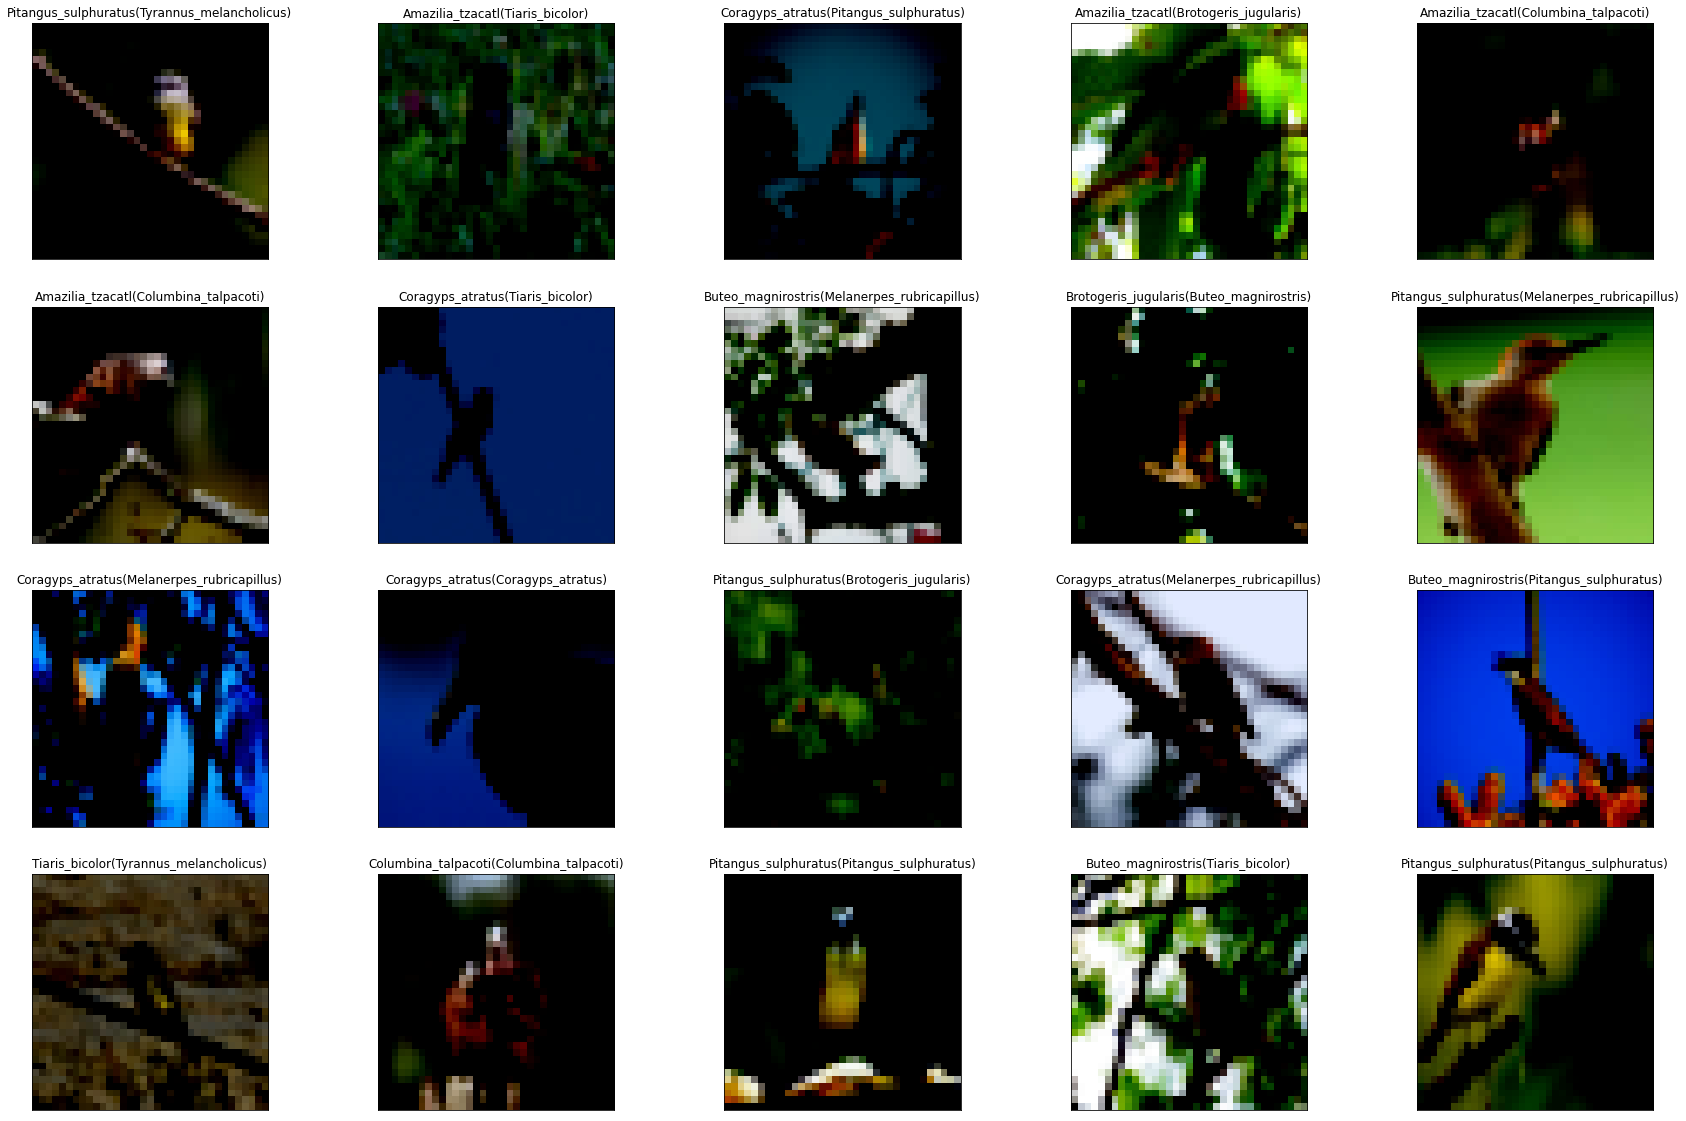

In [ ]:
fig=plt.figure(figsize=(30,20))

for idx in np.arange(20):
    ax=fig.add_subplot(4,5,idx+1,xticks=[],yticks=[])

    plt.imshow(im_convert(images[idx]))
    print('----------------------------------------------')
    print("prediccion "+str(classes[preds[idx].item()]))
    print("Real "+str(classes[labels[idx].item()]))
    print('----------------------------------------------')


    ax.set_title("{}({})".format(str(classes[preds[idx].item()]),str(classes[labels[idx].item()]),color=("green" if preds[idx]==labels[idx] else "red")))
plt.show()

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in test_iterator:
        images, labels = data
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print('Accuracy of the network on the 100 test images: %d %%' % (
    100 * correct / total))

Accuracy of the network on the 100 test images: 21 %


In [ ]:
class_correct = list(0. for i in range(9))
class_total = list(0. for i in range(9))
with torch.no_grad():
    for data in test_iterator:
        images, labels = data
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        c = (predicted == labels).squeeze()
        for i in range(4):
            label = labels[i]
            class_correct[label] += c[i].item()
            class_total[label] += 1


for i in range(9):
    print('Accuracy of %5s : %2d %%' % (
        classes[i], 100 * class_correct[i] / class_total[i]))

Accuracy of Amazilia_tzacatl :  0 %
Accuracy of Brotogeris_jugularis : 33 %
Accuracy of Buteo_magnirostris : 16 %
Accuracy of Columbina_talpacoti :  0 %
Accuracy of Coragyps_atratus : 33 %
Accuracy of Melanerpes_rubricapillus : 33 %
Accuracy of Pitangus_sulphuratus :  0 %
Accuracy of Tiaris_bicolor :  0 %
Accuracy of Tyrannus_melancholicus :  0 %


In [ ]:
import glob
torch.save(model.state_dict(), 'my_modeloP220Lenet.pkl')
#torch.save(model, glob.glob("./modelo.pkl"))


In [ ]:
import glob
torch.save(model.state_dict(), 'my_modeloP220Lenet.pt')
#torch.save(model, glob.glob("./modelo.pkl"))

In [ ]:

dataiter=iter(test_iterator)

images,labels=dataiter.next()
print(labels)
print(preds)

tensor([6, 1, 5, 8, 4, 6, 8, 3, 2, 2, 2, 4, 6, 2, 0, 8, 8, 3, 0, 4, 3, 1, 5, 2,
        1, 6, 4, 5, 2, 0, 8, 1, 8, 7, 6, 2, 8, 7, 3, 4, 3, 5, 1, 7, 1, 0, 8, 6,
        0, 6, 5, 0, 8, 7, 3, 7, 8, 1, 1, 0, 3, 5, 2, 2])
tensor([6, 0, 4, 0, 0, 0, 4, 2, 1, 6, 4, 4, 6, 4, 2, 7, 3, 6, 2, 6, 0, 7, 6, 6,
        2, 8, 0, 4, 4, 2, 6, 2, 6, 6, 4, 5, 4, 4, 1, 6, 2, 3, 4, 7, 7, 4, 1, 4,
        4, 4, 1, 8, 3, 4, 1, 8, 4, 1, 6, 0, 0, 3, 0, 6])


In [ ]:
confusion_matrix(labels, preds)

array([[1, 0, 3, 0, 2, 0, 0, 0, 1],
       [1, 1, 2, 0, 1, 0, 1, 2, 0],
       [1, 1, 0, 0, 3, 1, 3, 0, 0],
       [2, 2, 2, 0, 0, 0, 1, 0, 0],
       [2, 0, 0, 0, 1, 0, 2, 0, 0],
       [0, 1, 0, 2, 2, 0, 1, 0, 0],
       [1, 0, 0, 0, 3, 0, 2, 0, 1],
       [0, 0, 0, 0, 2, 0, 1, 1, 1],
       [1, 1, 0, 2, 3, 0, 2, 1, 0]], dtype=int64)

In [ ]:
import itertools
from sklearn.metrics import plot_confusion_matrix

def plot_confusion_matrix(cm,
                          classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix very prettily.
    Normalization can be applied by setting `normalize=True`.
    """
    fig = plt.figure(figsize = (10, 10));
    ax = fig.add_subplot(1, 1, 1);
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)

    # Specify the tick marks and axis text
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90)
    plt.yticks(tick_marks, classes)

    # The data formatting
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.

    # Print the text of the matrix, adjusting text colour for display
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()



Confusion matrix, without normalization


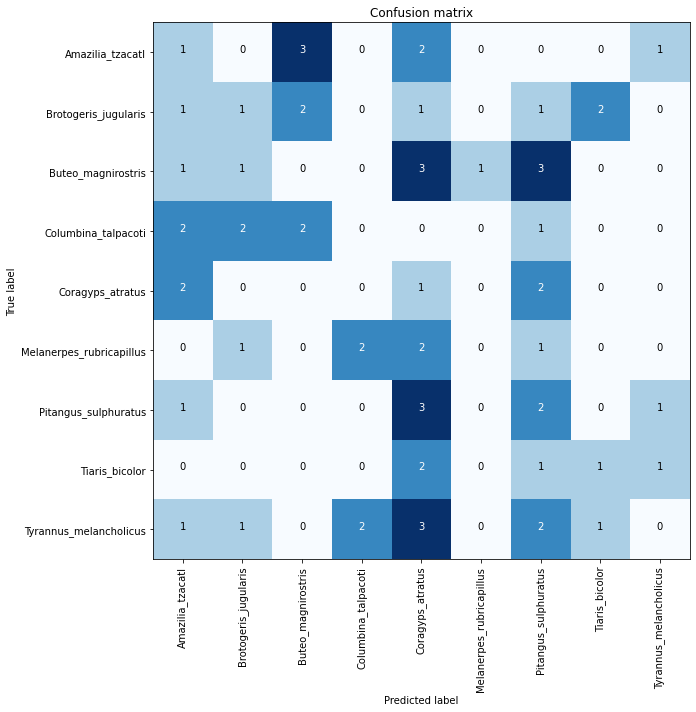

In [ ]:
cm = confusion_matrix(labels, preds);
plot_confusion_matrix(cm, classes)
